In [1]:
import rasterio
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds
from rasterio.windows import Window
from matplotlib import pyplot
import numpy as np
import tifffile

Open data and read it as array

In [2]:
path_LC_Hansen = 'C:/Users/minttu/Documents/LC_300m_0.05deg/ESACCI-LC-L4-LCCS-Map-300m-P1Y-2000-Resample_0.05deg.tif'

In [3]:
path_GLC = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_E0-E5/GLC_FCS30D_20002022_E0N10_Annual.tif'

LH forest classification





GLC forest classification

  'Open_evergreen_broadleaved_forest', 51
  'Closed_evergreen_broadleaved_forest', 52
  'Open_deciduous_broadleaved_forest', 61
  'Closed_deciduous_broadleaved_forest', 62
  'Open_evergreen_needle_leaved_forest', 71
  'Closed_evergreen_needle_leaved_forest', 72
  'Open_deciduous_needle_leaved_forest', 81
  'Closed_deciduous_needle_leaved_forest',  82
  'Open_mixed_leaf_forest', 91
  'Closed_mixed_leaf_forest', 92

In [5]:
LCHansen2000 = rasterio.open(path_LC_Hansen)

In [6]:
GLC_FCS302000 = rasterio.open(path_GLC)

Show metadata

In [8]:
with tifffile.TiffFile(path_LC_Hansen) as tif:
    for page in tif.pages:
        print(page.tags)

TiffTag 256 ImageWidth @10 SHORT @18 = 7200
TiffTag 257 ImageLength @22 SHORT @30 = 3600
TiffTag 258 BitsPerSample @34 SHORT @42 = 32
TiffTag 259 Compression @46 SHORT @54 = LZW
TiffTag 262 PhotometricInterpretation @58 SHORT @66 = MINISBLACK
TiffTag 277 SamplesPerPixel @70 SHORT @78 = 1
TiffTag 284 PlanarConfiguration @82 SHORT @90 = CONTIG
TiffTag 317 Predictor @94 SHORT @102 = NONE
TiffTag 322 TileWidth @106 SHORT @114 = 256
TiffTag 323 TileLength @118 SHORT @126 = 256
TiffTag 324 TileOffsets @130 LONG[435] @1970 = (3870, 5735, 7600, 9465, 11330,
TiffTag 325 TileByteCounts @142 LONG[435] @230 = (1865, 1865, 1865, 1865, 2051,
TiffTag 339 SampleFormat @154 SHORT @162 = IEEEFP
TiffTag 33550 ModelPixelScaleTag @166 DOUBLE[3] @3710 = (0.05, 0.05, 0.0)
TiffTag 33922 ModelTiepointTag @178 DOUBLE[6] @3734 = (0.0, 0.0, 0.0, -180.0, 9
TiffTag 34735 GeoKeyDirectoryTag @190 SHORT[32] @3782 = (1, 1, 0, 7, 1024, 0, 1
TiffTag 34736 GeoDoubleParamsTag @202 DOUBLE[2] @3846 = (298.257223563, 6378137


In [11]:
with tifffile.TiffFile(path_GLC) as tif:
    metadata = tif.imagej_metadata  # if present
    print(metadata)

None


left → min X (longitude or easting)
right → max X
bottom → min Y (latitude or northing)
top → max Y

In [12]:
bounds = LCHansen2000.bounds
print(bounds)

BoundingBox(left=-180.0, bottom=-90.0, right=180.0, top=90.0)


In [13]:
bounds2 = GLC_FCS302000.bounds
print(bounds2)

BoundingBox(left=0.0, bottom=4.99979746553392, right=5.00020253446608, top=10.0)


In [29]:
array = LCHansen2000.read(1)
array.shape
print(array[:-50, :-50])

[[210. 210. 210. ... 210. 210. 210.]
 [210. 210. 210. ... 210. 210. 210.]
 [210. 210. 210. ... 210. 210. 210.]
 ...
 [220. 220. 220. ... 220. 220. 220.]
 [220. 220. 220. ... 220. 220. 220.]
 [220. 220. 220. ... 220. 220. 220.]]


In [30]:
array2 = GLC_FCS302000.read(1)
array2.shape
print(array[:-50, :-50])

[[210. 210. 210. ... 210. 210. 210.]
 [210. 210. 210. ... 210. 210. 210.]
 [210. 210. 210. ... 210. 210. 210.]
 ...
 [220. 220. 220. ... 220. 220. 220.]
 [220. 220. 220. ... 220. 220. 220.]
 [220. 220. 220. ... 220. 220. 220.]]


In [16]:
LCHansen2000.crs

CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]')

In [17]:
GLC_FCS302000.crs

CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]')

In [33]:
mask = (array >= 51) & (array <= 92)
# Apply mask (set others to NaN for visualization)
filtered2 = np.where(mask, array, np.nan)

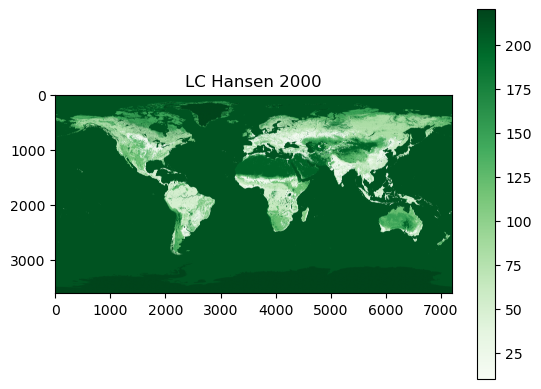

In [34]:
pyplot.imshow(array, cmap='Greens')
pyplot.title("LC Hansen 2000")
pyplot.colorbar()

Plot data and see coordinate information

In [35]:
mask = (array2 >= 51) & (array2 <= 92)
# Apply mask (set others to NaN for visualization)
filtered2 = np.where(mask, array2, np.nan)

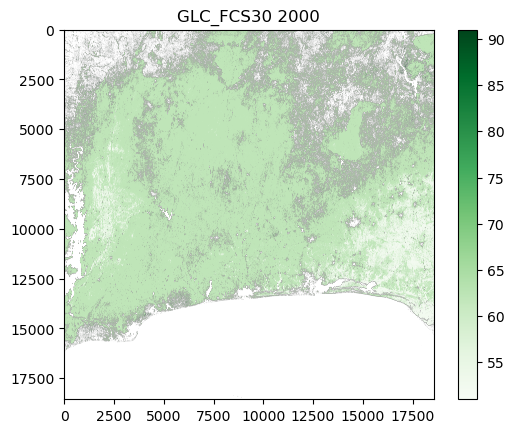

In [36]:
pyplot.imshow(filtered2, cmap='Greens')
pyplot.title("GLC_FCS30 2000")
pyplot.colorbar()

Define bounding box for LC Hansen

In [37]:
minx, miny, maxx, maxy = 0.0, 4.999797465533919, 5.000202534466081, 10.0

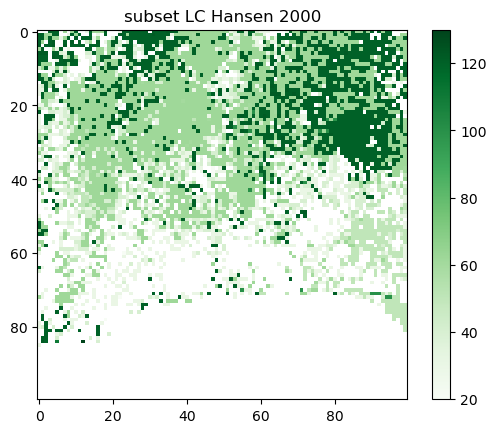

In [43]:
with rasterio.open(path_LC_Hansen) as src:
    window = from_bounds(minx, miny, maxx, maxy, src.transform)
    subset = src.read(1, window=window)

mask = (subset >= 20) & (subset <= 150) 
# Apply mask (set others to NaN for visualization)
filtered3 = np.where(mask, subset, np.nan)

pyplot.imshow(filtered3, cmap='Greens')
pyplot.title("subset LC Hansen 2000")
pyplot.colorbar()